# 09 - The chosen model on the primary test set

Notebook 08 picked the Elastic Net with six features, using cross-validation on the training cells only. Here it is fitted on all 41 training cells and measured on the 43 primary test cells.

The model and its settings were fixed before this notebook was written. Nothing here is tuned, and nothing gets changed because of what the test set shows. The paper's straight line (model B) and the mean baseline (A) are scored next to it for comparison.

The later batch (secondary test) is still untouched. That's step 3.6.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

data = pd.read_csv("../data/features_stage3.csv", index_col="cell_id")
train = data[data["split"] == "train"]
test = data[data["split"] == "test_primary"]

ALL = ["log_var", "q2", "q_max_minus_q2", "ir_change", "charge_time_first5", "t_avg_mean"]
print(len(train), "training cells,", len(test), "primary test cells")

41 training cells, 43 primary test cells


## Fit on the training cells

Same recipe as in notebook 08.

In [2]:
def elastic_net():
    inner = KFold(n_splits=5, shuffle=True, random_state=1)
    return make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9, 1.0], cv=inner, max_iter=50000))


y_train = np.log10(train["cycle_life"])
line = LinearRegression().fit(train[["log_var"]], y_train)
net = elastic_net().fit(train[ALL], y_train)

print(f"Elastic Net: alpha = {net[-1].alpha_:.4f}, l1_ratio = {net[-1].l1_ratio_}")
pd.Series(net[-1].coef_, index=ALL, name="coefficient").round(4)

Elastic Net: alpha = 0.0479, l1_ratio = 0.1


log_var              -0.1152
q2                    0.0278
q_max_minus_q2       -0.0195
ir_change             0.0000
charge_time_first5    0.0341
t_avg_mean           -0.0000
Name: coefficient, dtype: float64

## Scores

Predictions are turned back from log10 into cycles before the error is measured.

In [3]:
def predict(d):
    return pd.DataFrame({
        "A: mean": train["cycle_life"].mean(),
        "B: log_var line": 10 ** line.predict(d[["log_var"]]),
        "D: Elastic Net": 10 ** net.predict(d[ALL]),
    }, index=d.index)


def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))


def mape(y, p):
    return np.mean(np.abs(y - p) / y) * 100


pred_test = predict(test)
sets = {
    "train": (train, predict(train)),
    "primary test": (test, pred_test),
    "primary test without b2c1": (test.drop(index="b2c1"), pred_test.drop(index="b2c1")),
}
rows = []
for set_name, (d, p) in sets.items():
    for model in p.columns:
        rows.append({"set": set_name, "model": model,
                     "RMSE (cycles)": rmse(d["cycle_life"], p[model]),
                     "MAPE (%)": mape(d["cycle_life"], p[model])})
scores = pd.DataFrame(rows)
scores.pivot(index="model", columns="set", values="RMSE (cycles)").round(1)[list(sets)]

set,train,primary test,primary test without b2c1
model,,,
A: mean,323.1,392.8,389.1
B: log_var line,103.6,137.9,138.3
D: Elastic Net,76.2,113.7,111.4


In [4]:
scores.pivot(index="model", columns="set", values="MAPE (%)").round(1)[list(sets)]

set,train,primary test,primary test without b2c1
model,,,
A: mean,33.5,39.5,31.9
B: log_var line,14.1,14.7,13.2
D: Elastic Net,10.0,12.8,10.1


## How sure is the difference?

43 cells is not many, so the test cells are resampled with replacement 5,000 times (same idea as in notebook 06). Both models are scored on the same resampled cells each time, so their difference can be looked at directly.

In [5]:
rng = np.random.default_rng(0)
y = test["cycle_life"].values
p_line = pred_test["B: log_var line"].values
p_net = pred_test["D: Elastic Net"].values

boot_line, boot_net = [], []
for _ in range(5000):
    k = rng.integers(0, len(y), len(y))
    boot_line.append(rmse(y[k], p_line[k]))
    boot_net.append(rmse(y[k], p_net[k]))
boot_line, boot_net = np.array(boot_line), np.array(boot_net)

for name, b in [("B: log_var line", boot_line), ("D: Elastic Net", boot_net)]:
    low, high = np.percentile(b, [2.5, 97.5])
    print(f"{name}: 95% range {low:.0f} to {high:.0f} cycles")

diff = boot_line - boot_net
low, high = np.percentile(diff, [2.5, 97.5])
print(f"B minus D: {rmse(y, p_line) - rmse(y, p_net):.1f} cycles, 95% range {low:.0f} to {high:.0f}")
print(f"D has the lower RMSE in {np.mean(diff > 0) * 100:.1f}% of the resamples")

closer = np.abs(p_net - y) < np.abs(p_line - y)
print(f"cell by cell, D is closer than B for {closer.sum()} of the {len(y)} test cells")

B: log_var line: 95% range 92 to 191 cycles
D: Elastic Net: 95% range 73 to 160 cycles
B minus D: 24.2 cycles, 95% range 8 to 36
D has the lower RMSE in 99.8% of the resamples
cell by cell, D is closer than B for 30 of the 43 test cells


## Predicted vs actual

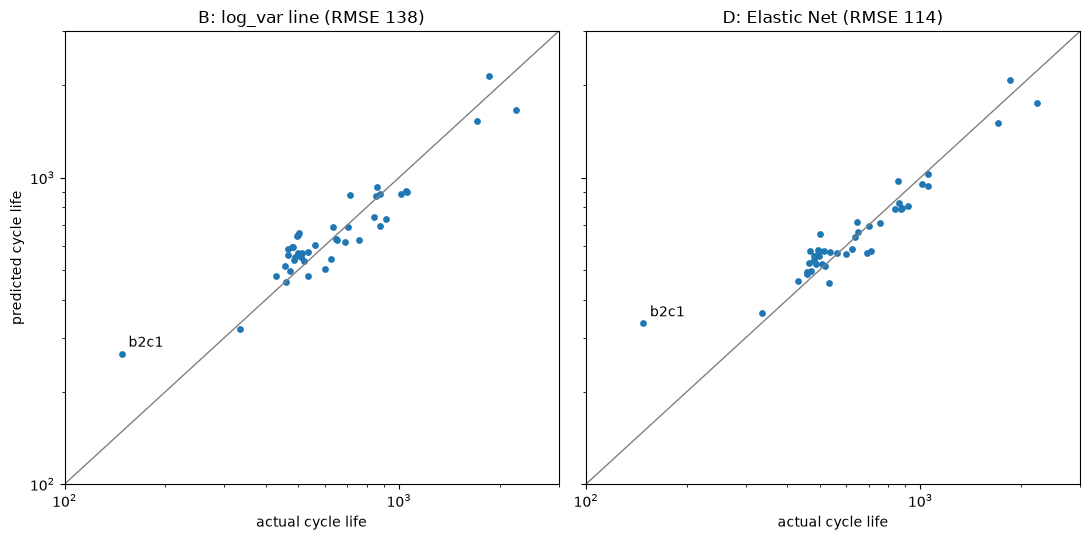

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
lims = [100, 3000]
for ax, model in zip(axes, ["B: log_var line", "D: Elastic Net"]):
    ax.scatter(test["cycle_life"], pred_test[model], s=15)
    ax.plot(lims, lims, color="grey", linewidth=1)
    ax.annotate("b2c1", (test.loc["b2c1", "cycle_life"], pred_test.loc["b2c1", model]), textcoords="offset points", xytext=(5, 5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("actual cycle life")
    ax.set_title(f"{model} (RMSE {rmse(test['cycle_life'], pred_test[model]):.0f})")
axes[0].set_ylabel("predicted cycle life")
plt.tight_layout()
plt.savefig("../reports/figures/pred_vs_actual_primary.png", dpi=120)
plt.show()

## Where the errors are

Notebook 06 found two weak spots of the straight line: the three test cells that live past 1,500 cycles, and the cells around 450 to 550 cycles, which it predicts too long. Same checks for both models.

In [7]:
errors = pred_test[["B: log_var line", "D: Elastic Net"]].sub(test["cycle_life"], axis=0)
table = errors.round(0).astype(int)
table.insert(0, "actual", test["cycle_life"].astype(int))
worst = errors["D: Elastic Net"].abs().sort_values(ascending=False).index[:6]
print("largest errors of D (predicted minus actual, cycles):")
table.loc[worst]

largest errors of D (predicted minus actual, cycles):


,actual,B: log_var line,D: Elastic Net
cell_id,,,
b1c2,2237,-573,-481
b1c0,1852,292,226
b1c4,1709,-175,-207
b2c1,148,118,187
b2c20,502,157,155
b2c47,713,164,-139


In [8]:
long_cells = test["cycle_life"] > 1500
mid_cells = test["cycle_life"].between(450, 550)
rest = ~long_cells
for model in ["B: log_var line", "D: Elastic Net"]:
    e = errors[model]
    print(model)
    print(f"  {long_cells.sum()} cells above 1,500 cycles: RMSE {np.sqrt(np.mean(e[long_cells] ** 2)):.0f}")
    print(f"  the other {rest.sum()} cells: RMSE {np.sqrt(np.mean(e[rest] ** 2)):.1f}")
    print(f"  {mid_cells.sum()} cells at 450 to 550 cycles: {(e[mid_cells] > 0).sum()} predicted too long, mean error {e[mid_cells].mean():+.0f}")

B: log_var line
  3 cells above 1,500 cycles: RMSE 385
  the other 40 cells: RMSE 96.6
  18 cells at 450 to 550 cycles: 16 predicted too long, mean error +69
D: Elastic Net
  3 cells above 1,500 cycles: RMSE 329
  the other 40 cells: RMSE 76.0
  18 cells at 450 to 550 cycles: 16 predicted too long, mean error +50


## Save

In [9]:
out = pred_test.round(1)
out.insert(0, "cycle_life", test["cycle_life"])
out.to_csv("../reports/predictions_primary_test.csv")
scores.round(2).to_csv("../reports/test_results_stage3.csv", index=False)
print("saved", len(out), "predictions")

saved 43 predictions


## Notes

- On the primary test set the Elastic Net gets an RMSE of 113.7 cycles (12.8%), against 137.9 cycles (14.7%) for the paper's straight line. That's 24.2 cycles less.
- The difference holds up when the test cells are resampled: its 95% range is 8 to 36 cycles, and the Elastic Net has the lower RMSE in 99.8% of the resamples. Cell by cell it is closer for 30 of the 43. So the gain is real, but its size is uncertain: anywhere from small to about a quarter of the error.
- Each model's own number is still loose. The range for the Elastic Net is 73 to 160 cycles, and for the line 92 to 191.
- Cross-validation in notebook 08 said 81.6 cycles for the Elastic Net and 108.0 for the line. The test numbers are about 30 cycles higher for both, mostly because of the long-lived cells below. The order of the models and the size of the gap (26 in CV, 24 here) came out the same, which is what the cross-validation was for.
- The long-lived cells are still the weak spot. The three test cells above 1,500 cycles have an RMSE of 329 (line: 385), and on the other 40 cells the Elastic Net is at 76.0 (line: 96.6). b1c2 (2,237 cycles) is predicted 481 cycles too short. Extra features don't fix a range that has one training cell in it.
- The cells at 450 to 550 cycles are still predicted too long: 16 of 18, by 50 cycles on average (line: 69). Better, not gone.
- b2c1 got worse. It lives 148 cycles and the Elastic Net predicts 335 (line: 266). Without it the Elastic Net's percentage error drops from 12.8% to 10.1%. No training cell dies before cycle 300, so both models are guessing there.
- For reference, the paper's own "full" model with more features is quoted at 100 cycles on this test set (Attia et al. 2021). My features are simpler and not the same ones, so 113.7 isn't a reproduction of that number, just a sign that it's in a sensible range.
- The test set has now been used for the final score of the chosen model. I'm not going back to change features or settings because of what it showed.
